# Cohort, duration and Aalen-Johansen estimators on CEREP

**Question:** When the annual tables show no default in a thin grade, is its PD really zero, and which estimator (cohort, duration, Aalen-Johansen or EM) comes closest to the true PD when the truth is known?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (cohorts, the one-year PD and the long-run average)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- pool the annual cohort tables into one matrix with Anderson and Goodman's estimator and put three intervals (Wald, Agresti-Coull, Jeffreys) on a thin grade's PD;
- say what the cohort estimator cannot see (what happens inside the year) and what the duration estimator uses instead (every jump and the time spent in each grade);
- compute a duration generator, an Aalen-Johansen matrix and an EM generator on a rating-path dataset whose true generator is known, and read each against the truth;
- explain why the duration estimator gives a non-zero PD to a grade where the cohort estimator saw no default;
- read the 200-draw evidence of how often each estimator returns exactly zero and how large its error is.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import embedding, estimators, intervals
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files of case C04, all derived from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: the S&P annual cohorts (26 tables, 2000 to 2025), the pooled matrix and the generators.
- `data/derived/C04/fitch.json`: the same for Fitch (24 annual cohorts), for a comparison across agencies.
- `data/derived/C04/models-transitions.json`: the generator the case fitted to S&P's counts by EM (`fit.generator.q`) and the number of obligors it simulates from (`fit.generator.obligors`). This generator is the **known truth** of the second half of the notebook.
- `data/derived/C04/markov.json`: the committed simulation study, 200 seeded datasets drawn from that generator, with the bias and the error of six estimators.

CEREP publishes snapshots (the ratings on 1 January and on 31 December), never individual rating paths, so the continuous-time estimators cannot be run on the real tables: they need the date of every jump. That is why the notebook draws **one** dataset of rating paths from the committed generator with the engine's `RatingPaths`: it is small (a fraction of a second), seeded, and every estimator can be compared with the generator that made it.

The next cell loads the files and prints what they hold.

In [2]:
# Load the four artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, fitch = load("sp.json"), load("fitch.json")
models, markov = load("models-transitions.json"), load("markov.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]

print("S&P annual cohorts:", len(cohorts), "| Fitch:", len(fitch["outputs"]["cohorts"]))
print("obligors the truth generator simulates, by grade:",
      models["fit"]["generator"]["obligors"])
print("simulation study: draws:", markov["outputs"]["design"]["reps"],
      "| years:", markov["outputs"]["design"]["years"])

S&P annual cohorts: 26 | Fitch: 24
obligors the truth generator simulates, by grade: [75, 822, 1814, 1756, 1054, 1391, 201]
simulation study: draws: 200 | years: 5


## Method

### Step 1: pooling the annual cohorts

One cohort gives each grade a few hundred ratings, and a rare transition may not appear in it. Anderson and Goodman (1957, equation 2.8) pool the periods under time homogeneity: add the corresponding entries of the count tables and divide each row by its total,

$$\hat p_{ij} = \frac{\sum_t N_{ij}(t)}{\sum_t \sum_k N_{ik}(t)}$$

Each year's withdrawn ratings are removed first (the industry treatment of notebook 01). Years with more ratings weigh more, which is why the pooled rate is not the average of the yearly rates of notebook 01.

The next cell calls the engine's `pooled_cohort` on the 26 tables and prints, per grade, the ratings pooled, the defaults among them and the pooled PD.

In [3]:
# Pool the 26 annual tables with the engine, the withdrawn ratings removed year by year
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
pooled = estimators.pooled_cohort(tables, gone, treatment="exclude")
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]

print(f"{'grade':8s}{'ratings pooled':>22s}{'defaults':>16s}{'pooled PD':>14s}")
for g in range(7):
    print(f"{grades[g]:8s}{ratings[g]:22.0f}{defaults[g]:16.0f}{100 * pooled['matrix'][g, -1]:13.4f}%")

grade           ratings pooled        defaults     pooled PD
AAA                       1895               0       0.0000%
AA                       20192               1       0.0050%
A                        45073              13       0.0288%
BBB                      42854              35       0.0817%
BB                       24842              86       0.3462%
B                        31712             372       1.1731%
CCC-C                     3731             301       8.0675%


### Step 2: an interval on a thin grade

The pooled PD of AA rests on one default in about twenty thousand ratings, and AAA's on none. A point estimate says nothing of that. The engine offers three intervals at 95%, all in `transitions.intervals`: the Wald interval $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$, the Agresti-Coull interval, which adds $z^2$ pseudo-observations before applying the Wald formula, and the equal-tailed Jeffreys interval, the quantiles $\mathrm{Beta}(D + \tfrac12,\, n - D + \tfrac12)$ (Brown, Cai and DasGupta, 2001). Schuermann and Hanson (2004) use the first two for PDs by grade.

The next cell calls the three on the pooled defaults and ratings of the previous step and prints the upper bound each puts on the PD of the four best grades.

In [4]:
# The three 95% intervals of the engine on the pooled defaults and ratings
wald = intervals.pd_wald(defaults, ratings, level=0.95)
agresti = intervals.pd_agresti_coull(defaults, ratings, level=0.95)
jeffreys = intervals.pd_jeffreys(defaults, ratings, level=0.95)
bands = {"Wald": wald, "Agresti-Coull": agresti, "Jeffreys": jeffreys}

print(f"{'grade':8s}{'defaults':>14s}" + "".join(f"{k:>22s}" for k in bands))
for g in range(4):
    cells = [f"{100 * b['lower'][g]:.3f}% to {100 * b['upper'][g]:.3f}%" for b in bands.values()]
    print(f"{grades[g]:8s}{defaults[g]:14.0f}" + "".join(f"{c:>22s}" for c in cells))

grade         defaults                  Wald         Agresti-Coull              Jeffreys
AAA                  0      0.000% to 0.000%      0.000% to 0.244%      0.000% to 0.132%
AA                   1      0.000% to 0.015%      0.000% to 0.031%      0.001% to 0.023%
A                   13      0.013% to 0.045%      0.016% to 0.050%      0.016% to 0.048%
BBB                 35      0.055% to 0.109%      0.058% to 0.114%      0.058% to 0.112%


The next cell draws the upper bound of each interval for the four best grades, with its value written on the bar.

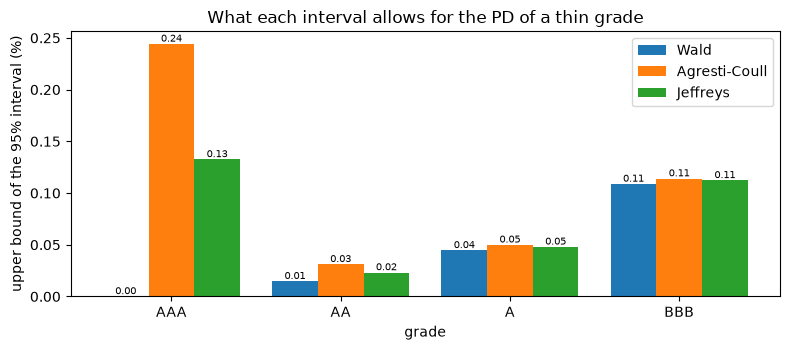

In [5]:
# Draw the upper bound of the three intervals for AAA, AA, A and BBB
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(4)
for k, (name, band) in enumerate(bands.items()):
    heights = 100 * band["upper"][:4]
    ax.bar(x + (k - 1) * 0.27, heights, 0.27, label=name)
    for xi, h in zip(x + (k - 1) * 0.27, heights):
        ax.text(xi, h, f"{h:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(grades[:4])
ax.set_xlabel("grade")
ax.set_ylabel("upper bound of the 95% interval (%)")
ax.set_title("What each interval allows for the PD of a thin grade")
ax.legend()
fig.tight_layout()
plt.show()

AAA has 1,895 pooled ratings and no default, and the Wald interval turns that into an upper bound of exactly zero: the estimator is certain of a PD that rests on nothing. Agresti-Coull and Jeffreys keep an upper bound of 0.244% and 0.132%, which is the honest statement that no default in 1,895 ratings is compatible with a PD of a few hundredths of a percent. For AA the three intervals agree to within a factor of two; from A down they are close. The figure cannot say which interval covers the truth most often when the grade is thin; that needs a known truth, which is what the next steps build.

### Step 3: a dataset whose truth is known

The generator the case fitted to S&P's counts is the truth here: a valid generator $Q$ whose one-year PD by grade is the default column of $\exp(Q)$. The next cell reads it from `models-transitions.json`, checks with the engine that it is a generator (non-negative off-diagonal entries, rows summing to zero, default absorbing) and prints the true one-year PD and the mean time an obligor spends in each grade before leaving it, $-1/q_{ii}$.

In [6]:
# Read the truth generator, ask the engine whether it is one, and compute its one-year PD
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
pd_true = expm(q_true)[:7, -1]
dwell = -1.0 / np.diag(q_true)[:7]

print("valid generator:", embedding.is_generator(q_true))
print(f"{'grade':8s}{'true PD':>16s}{'mean years in grade':>32s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:15.4f}%{dwell[g]:32.2f}")

valid generator: True
grade            true PD             mean years in grade
AAA              0.0066%                            5.12
AA               0.0049%                            8.51
A                0.0288%                           15.69
BBB              0.0817%                           13.36
BB               0.3462%                            7.22
B                1.1731%                            6.59
CCC-C            8.0618%                            2.89


`RatingPaths` draws, with a seeded random stream, the rating path of every obligor over five years, observed at annual snapshots like CEREP. The draw is exact: the engine simulates the continuous-time chain, so the paths hold the date of every jump, which a real CEREP table does not. CEREP publishes snapshots, never individual paths, so the continuous-time estimators cannot be run on the real tables, and this draw is what lets every estimator meet a generator that made it.

In [7]:
# Draw one seeded dataset of rating paths observed at annual snapshots
snapshots = tuple(float(t) for t in range(6))
generator = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots)
data = generator.draw(np.random.default_rng(20261021))
segments, steps = data["segments"], data["steps"]

print("obligors:", int(sum(n_obligors)))
print("segments (one per stay in a grade):", len(segments["obligor"]))
print("annual snapshot tables:", len(steps))

obligors: 7113
segments (one per stay in a grade): 10953
annual snapshot tables: 5


### Step 4: the cohort estimator against the duration estimator

On the same obligors, two readings. The cohort estimator sees only the five annual snapshots: it pools them with equation 2.8 and reads the default column. The duration estimator (Lando and Skodeberg, 2002) uses every jump and the time each obligor spent in each grade. For a time-homogeneous chain observed continuously the likelihood is maximised by

$$\hat q_{ij} = \frac{K_{ij}}{S_i}, \quad i \neq j, \qquad \hat q_{ii} = -\sum_{j \neq i} \hat q_{ij}$$

with $K_{ij}$ the number of observed jumps from $i$ to $j$ and $S_i$ the total time spent in $i$; the one-year matrix is $P = \exp(\hat Q)$. A rating can go AAA to AA to A to ... to default inside one year, and the duration estimator sees every step, while a snapshot sees only the beginning and the end.

The next cell runs both on the draw, prints the jumps out of AAA and the time spent in each grade, and puts the two PDs beside the truth.

In [8]:
# The duration generator from the paths (K/S) and the pooled cohort estimator from the five snapshots
dur = estimators.duration_generator(segments, len(states))
q_dur = dur["generator"]
cohort_5 = estimators.pooled_cohort([s["counts"] for s in steps])
pd_cohort = cohort_5["matrix"][:7, -1]
pd_dur = expm(q_dur)[:7, -1]

print("jumps out of AAA, to AAA ... D:", np.array(dur["jumps"])[0].astype(int))
print("obligor-years spent in each grade:", np.round(np.array(dur["holding"])[:7], 1))
print(f"{'grade':8s}{'truth':>12s}{'cohort':>12s}{'duration':>12s}{'defaults seen':>20s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * pd_cohort[g]:11.4f}%"
          f"{100 * pd_dur[g]:11.4f}%{cohort_5['counts'][g, -1]:20.0f}")

jumps out of AAA, to AAA ... D: [ 0 54  0  0  0  1  1  0]
obligor-years spent in each grade: [ 240.2 3674.1 9263.6 8977.5 5090.  6432.9 1313.1]
grade          truth      cohort    duration       defaults seen
AAA          0.0066%     0.0000%     0.0204%                   0
AA           0.0049%     0.0000%     0.0013%                   0
A            0.0288%     0.0217%     0.0257%                   2
BBB          0.0817%     0.0895%     0.0932%                   8
BB           0.3462%     0.4480%     0.4808%                  23
B            1.1731%     1.3231%     1.2517%                  86
CCC-C        8.0618%     8.7678%     8.9439%                 111


The next cell draws each estimate as a multiple of the true PD of its grade, so that a line at one is a perfect estimate.

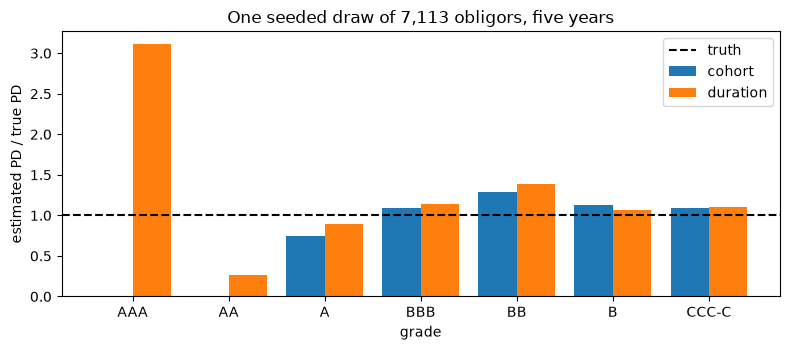

In [9]:
# Draw the cohort and duration estimates as multiples of the true PD, by grade
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(7)
ax.bar(x - 0.2, pd_cohort / pd_true, 0.4, color="tab:blue", label="cohort")
ax.bar(x + 0.2, pd_dur / pd_true, 0.4, color="tab:orange", label="duration")
ax.axhline(1.0, color="black", linestyle="--", label="truth")
ax.set_xticks(x)
ax.set_xticklabels(grades)
ax.set_xlabel("grade")
ax.set_ylabel("estimated PD / true PD")
ax.set_title("One seeded draw of 7,113 obligors, five years")
ax.legend()
fig.tight_layout()
plt.show()

Neither estimator saw an AAA default: the jump count out of AAA to default is zero. The cohort estimator therefore reads exactly zero for AAA and AA, while the duration estimator saw AAA obligors jump to B and to CCC-C inside the year, and the matrix exponential chains those jumps with the default rates of B and CCC-C, so it returns a positive PD: 0.0204% for AAA against a true 0.0066%. One draw is one sample, so the duration number can sit above or below the truth, here above for AAA and below for AA. The figure shows who can be wrong in which direction; the size of the typical error needs many draws, which is Step 7.

### Step 5: Aalen-Johansen, without time homogeneity

The duration estimator assumes one generator for the whole period. Aalen and Johansen (1978) drop that: they estimate the transition matrix between any two dates $s < t$ as the product, over the observed jump times $u$ in $(s, t]$, of the identity plus the Nelson-Aalen increment,

$$\hat P(s, t) = \prod_{s < u \le t} \bigl(I + d\hat A(u)\bigr), \qquad d\hat A_{ij}(u) = \frac{dN_{ij}(u)}{Y_i(u-)}$$

with $dN_{ij}(u)$ the jumps from $i$ to $j$ at $u$ and $Y_i(u-)$ the obligors in $i$ just before $u$. It needs no generator and no homogeneity, and being a product over time it satisfies the Chapman-Kolmogorov identity $\hat P(0, 2) = \hat P(0, 1)\,\hat P(1, 2)$ exactly.

The next cell computes the matrices for the first, the second and the first two years, prints the largest gap in the Chapman-Kolmogorov identity and sets the one-year PDs of the two single years beside the truth and the duration estimate.

In [10]:
# Aalen-Johansen matrices on the same paths and the PD they give for each single year
aj01 = estimators.aalen_johansen(segments, len(states), 0.0, 1.0)["matrix"]
aj12 = estimators.aalen_johansen(segments, len(states), 1.0, 2.0)["matrix"]
aj02 = estimators.aalen_johansen(segments, len(states), 0.0, 2.0)["matrix"]
gap = float(np.abs(aj02 - aj01 @ aj12).max())

print("largest gap between P(0,2) and P(0,1) P(1,2):", f"{gap:.1e}")
print(f"{'grade':8s}{'truth':>12s}{'AJ P(0,1)':>12s}{'AJ P(1,2)':>12s}{'duration':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * aj01[g, -1]:11.4f}%"
          f"{100 * aj12[g, -1]:11.4f}%{100 * pd_dur[g]:11.4f}%")

largest gap between P(0,2) and P(0,1) P(1,2): 1.1e-15
grade          truth   AJ P(0,1)   AJ P(1,2)    duration
AAA          0.0066%     0.0956%     0.0001%     0.0204%
AA           0.0049%     0.0005%     0.0027%     0.0013%
A            0.0288%     0.0081%     0.0604%     0.0257%
BBB          0.0817%     0.0178%     0.1324%     0.0932%
BB           0.3462%     0.5330%     0.6910%     0.4808%
B            1.1731%     1.5360%     1.3384%     1.2517%
CCC-C        8.0618%     7.7028%    10.0631%     8.9439%


The product of the first-year and second-year matrices equals the two-year matrix to rounding, as the definition says. The two single years differ from each other and from the truth because they are two samples of one chain (the generator is time-homogeneous here), which is the noise the 200-draw study of Step 7 averages out. With a chain that changes over time the two columns would differ for a reason, and only Aalen-Johansen would follow it. It also shows its cost: with one year of data a rare transition is as thin for Aalen-Johansen as it is for the cohort estimator, and the duration estimator is steadier because it pools both years under one generator.

### Step 6: the EM generator, from snapshots only

A user of CEREP has no jump dates, only the annual tables. Bladt and Sorensen (2005), as Smith and dos Reis (2018) present it, give a generator by expectation-maximisation: it finds the generator whose matrix exponential makes the observed snapshot counts most likely, and the result is a valid generator by construction. The engine's `em_generator` takes the sequence of count tables with the length of each step.

The next cell runs it twice: on the five snapshot tables of the draw, where the truth is known, and on the 26 real S&P cohorts.

In [11]:
# EM generator on the simulated snapshots and on the 26 real S&P cohorts
em_sim = em_generator([{"counts": s["counts"], "dt": 1.0} for s in steps])
pd_em = expm(em_sim["generator"])[:7, -1]
em_real = em_generator([{"counts": t, "dt": 1.0} for t in tables])
pd_em_real = expm(em_real["generator"])[:7, -1]

print("simulated snapshots: iterations:", em_sim["iterations"], "| converged:", em_sim["converged"])
print("real S&P cohorts: iterations:", em_real["iterations"], "| converged:", em_real["converged"])
print(f"{'grade':8s}{'truth':>12s}{'EM draw':>14s}{'EM real data':>20s}{'pooled cohort':>22s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * pd_em[g]:13.4f}%"
          f"{100 * pd_em_real[g]:19.4f}%{100 * pooled['matrix'][g, -1]:21.4f}%")

simulated snapshots: iterations: 42 | converged: True
real S&P cohorts: iterations: 116 | converged: True
grade          truth       EM draw        EM real data         pooled cohort
AAA          0.0066%       0.0025%             0.0066%               0.0000%
AA           0.0049%       0.0021%             0.0049%               0.0050%
A            0.0288%       0.0212%             0.0288%               0.0288%
BBB          0.0817%       0.0894%             0.0817%               0.0817%
BB           0.3462%       0.4480%             0.3462%               0.3462%
B            1.1731%       1.3231%             1.1731%               1.1731%
CCC-C        8.0618%       8.7625%             8.0618%               8.0675%


The next cell draws the four estimates of the draw as multiples of the true PD, now with EM and the first Aalen-Johansen year beside the two of Step 4.

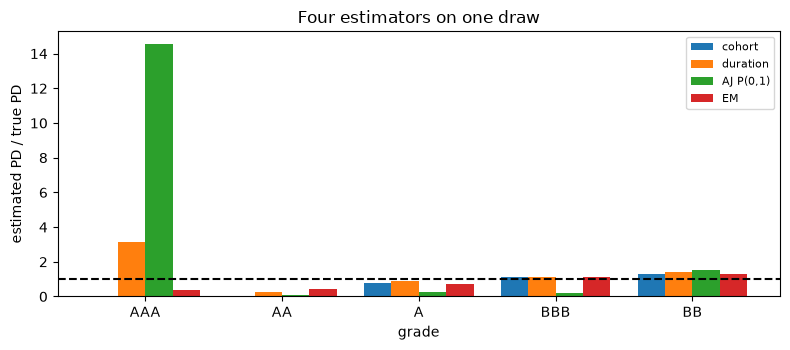

In [12]:
# Draw the four estimators of the draw as multiples of the true PD, grades AAA to BB
fig, ax = plt.subplots(figsize=(8, 3.6))
series = {"cohort": pd_cohort, "duration": pd_dur, "AJ P(0,1)": aj01[:7, -1], "EM": pd_em}
x = np.arange(5)
for k, (name, values) in enumerate(series.items()):
    ax.bar(x + (k - 1.5) * 0.2, values[:5] / pd_true[:5], 0.2, label=name)
ax.axhline(1.0, color="black", linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(grades[:5])
ax.set_xlabel("grade")
ax.set_ylabel("estimated PD / true PD")
ax.set_title("Four estimators on one draw")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

EM sees the same annual snapshots as the cohort estimator and does not recover the best grades either: it returns small positive PDs for AAA and AA, a valid generator by construction, but they come from the model and not from jumps it observed. From A to BB the four estimators sit near one, and the differences between them are of the order of the noise of a single draw. On the real S&P cohorts EM converges in 116 iterations to the generator this notebook uses as its truth (the case fitted it that way), and its PDs sit on the pooled cohort ones from A to BB. The figure shows one draw and cannot rank the estimators; the committed study of the next step can.

### Step 7: what 200 draws say

One draw proves nothing about an estimator. The case commits the study the harness ran: 200 seeded datasets from the same generator, each with its cohort, duration and EM estimate of the one-year PD, and for each grade the bias, the root mean squared error (RMSE) and the share of draws in which the estimate was exactly zero. The next cell reads `markov.json` and prints the RMSE relative to the true PD and the share of zero estimates. A relative RMSE of 1 means the typical error is as large as the PD itself.

In [13]:
# Read the 200-draw study: relative RMSE and share of zero estimates
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])
kinds = ("cohort", "duration", "em")
relative = {k: np.array(study[k]["rmse"]) / truth for k in kinds}
zero_share = {k: [z["rate"] for z in study[k]["zero"]] for k in kinds}

print("RMSE / true PD (rows: estimator, columns: grade)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
for k in kinds:
    print(f"{k:10s}" + "".join(f"{v:9.3f}" for v in relative[k]))
print("share of the 200 draws whose estimate is exactly zero")
for k in kinds:
    print(f"{k:10s}" + "".join(f"{v:9.2f}" for v in zero_share[k]))

RMSE / true PD (rows: estimator, columns: grade)
                AAA       AA        A      BBB       BB        B    CCC-C
cohort        5.609    2.184    0.529    0.386    0.227    0.114    0.098
duration      1.245    1.882    0.503    0.351    0.215    0.100    0.085
em            5.634    2.056    0.509    0.385    0.227    0.114    0.098
share of the 200 draws whose estimate is exactly zero
cohort         0.99     0.83     0.05     0.00     0.00     0.00     0.00
duration       0.00     0.00     0.00     0.00     0.00     0.00     0.00
em             0.00     0.00     0.00     0.00     0.00     0.00     0.00


The next cell draws both tables: the relative error by grade on a logarithmic scale, and the share of exact zeros.

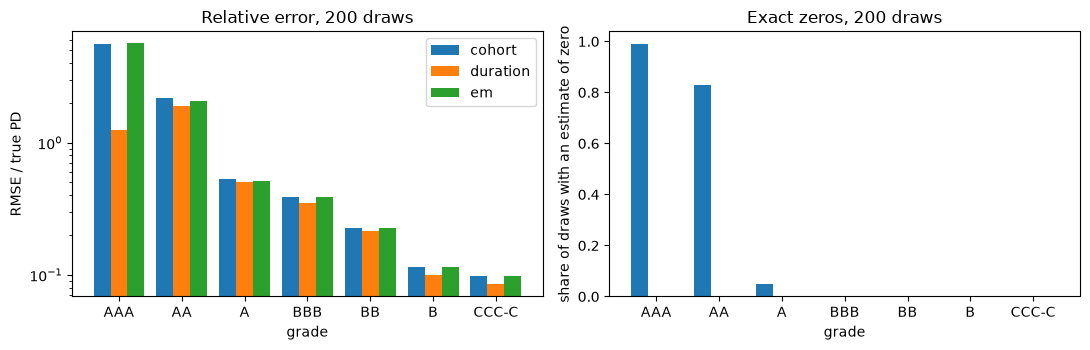

In [14]:
# Draw the relative RMSE (left) and the share of exactly-zero estimates (right) of the three estimators
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(7)
for k, name in enumerate(kinds):
    left.bar(x + (k - 1) * 0.27, relative[name], 0.27, label=name)
    right.bar(x + (k - 1) * 0.27, zero_share[name], 0.27, label=name)
left.set_yscale("log")
for ax in (left, right):
    ax.set_xticks(x)
    ax.set_xticklabels(grades)
    ax.set_xlabel("grade")
left.set_ylabel("RMSE / true PD")
right.set_ylabel("share of draws with an estimate of zero")
left.set_title("Relative error, 200 draws")
right.set_title("Exact zeros, 200 draws")
left.legend()
fig.tight_layout()
plt.show()

The left panel says that the choice of estimator matters where the data are thin and hardly at all elsewhere: for AAA the typical error of the cohort estimator is 5.6 times the PD and the duration estimator's is 1.25 times, while from A to CCC-C the three have similar relative errors, from about 0.5 at A to about 0.1 at B and CCC-C. The right panel gives the reason: in 99% of the draws the cohort estimate of AAA is exactly zero, and in 83% that of AA, against none for the duration estimator. EM sees the same snapshots as the cohort estimator and its error is the cohort estimator's. What the panels do not show is bias: a duration estimator that is never zero can still be too high, and the committed study carries those numbers beside the RMSE.

### Step 8: a second agency

The same pooled estimator runs on any agency's cohorts. Fitch's transition page has a default category, so its 24 annual cohorts pool exactly as S&P's 26 did; Moody's has none, so no PD can be read off a Moody's matrix. The next cell pools Fitch's tables with the engine and sets its pooled PD beside S&P's.

In [15]:
# Pool Fitch's tables with the same estimator and set its pooled PD beside S&P's
fitch_cohorts = fitch["outputs"]["cohorts"]
tables_f = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in fitch_cohorts]
gone_f = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in fitch_cohorts]
pooled_f = estimators.pooled_cohort(tables_f, gone_f, treatment="exclude")

print(f"{'grade':8s}{'S&P':>12s}{'Fitch':>12s}{'Fitch ratings':>18s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pooled['matrix'][g, -1]:11.3f}%"
          f"{100 * pooled_f['matrix'][g, -1]:11.3f}%{pooled_f['row_sizes'][g]:18.0f}")

grade            S&P       Fitch     Fitch ratings
AAA           0.000%      0.000%              1054
AA            0.005%      0.000%              3890
A             0.029%      0.000%             16922
BBB           0.082%      0.017%             23185
BB            0.346%      0.149%             10050
B             1.173%      0.521%              7677
CCC-C         8.068%      4.034%              1066


## Results

**Answer:** no, a thin grade with no observed default does not have a PD of zero, and the estimator decides how far from zero it reads. AAA rests on 1,895 pooled ratings and no default: the Wald interval has an upper bound of zero, Agresti-Coull 0.244% and Jeffreys 0.132%. On a seeded dataset whose true one-year PD for AAA is 0.0066%, the cohort estimator reads 0 and the duration estimator 0.0204%. Over 200 draws the cohort estimate of AAA is exactly zero in 99% of them (AA: 83%) and the duration one never is, and the duration estimator's error relative to the PD is 1.25 for AAA against 5.61 for the cohort estimator.

- **Pooling.** The 26 annual tables pool into one matrix: AA rests on one default in 20,192 ratings and B on 372 in 31,712.
- **From A to CCC-C the choice matters little.** The relative errors of the three estimators run from about 0.5 at A to about 0.1 at B and CCC-C, so the choice matters where the data are thin.
- **EM does not recover AAA.** The EM generator of the snapshots has a relative error of 5.63 for AAA, the cohort estimator's, and never returns zero: it is always a valid generator, but it sees the same annual snapshots.
- **Aalen-Johansen** gives a matrix for any pair of dates with no homogeneity assumption and satisfies P(0, 2) = P(0, 1) P(1, 2) up to rounding. Its two single years differ because they are two samples of one chain.
- **Real counts and a second agency.** EM on the 26 real S&P cohorts converges in 116 iterations. Fitch's pooled PDs are lower than S&P's in every grade from AA to CCC-C, over 24 cohorts against 26.

What this notebook does not show: whether the generator exists and which repair to use (notebook 03), whether the Markov assumption holds (notebook 04), or how the definition of default and the withdrawals bias a PD (notebook 10).

## Summary

- The cohort estimator pools annual snapshots and sees nothing that happens inside the year; the duration estimator uses every jump and the time in each grade; Aalen-Johansen drops time homogeneity; EM finds a valid generator from snapshots alone.
- On a thin grade the cohort estimator returns exactly zero most of the time and the Wald interval has width zero; the duration estimator and the Jeffreys interval do not.
- Estimators are compared on data whose truth is known, over many draws, never on one sample.
- A second agency's cohorts pool with the same call, and the differences between agencies show in the pooled PDs.

**What to try next.** Change the seed of the draw in Step 3 and watch the AAA estimates move; then read notebook 03 on the embedding problem.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Lando, D. and Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Aalen, O. O. and Johansen, S. (1978), An empirical transition matrix for non-homogeneous Markov chains based on censored observations, Scandinavian Journal of Statistics 5(3), 141-150.
- Bladt, M. and Sorensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), and Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627.